In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [5]:
columns = ["name", "MDVP:Fo(Hz)", "MDVP:Fhi(Hz)", "MDVP:Flo(Hz)", "MDVP:Jitter(%)",
           "MDVP:Jitter(Abs)", "MDVP:RAP", "MDVP:PPQ", "Jitter:DDP", "MDVP:Shimmer",
           "MDVP:Shimmer(dB)", "Shimmer:APQ3", "Shimmer:APQ5", "MDVP:APQ", "Shimmer:DDA",
           "NHR", "HNR", "status", "RPDE", "DFA", "spread1", "spread2", "D2", "PPE"]

df = pd.read_csv("../data/parkinsons.csv", header=None, names=columns)
print(df.shape)
df.head()

(196, 24)


,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
1,phon_R01_S01_1,119.99200,157.30200,74.99700,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,...,0.06545,0.02211,21.03300,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
2,phon_R01_S01_2,122.40000,148.65000,113.81900,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,...,0.09403,0.01929,19.08500,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
3,phon_R01_S01_3,116.68200,131.11100,111.55500,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,...,0.08270,0.01309,20.65100,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
4,phon_R01_S01_4,116.67600,137.87100,111.36600,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,...,0.08771,0.01353,20.64400,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975


In [6]:
print(df.tail())

               name MDVP:Fo(Hz) MDVP:Fhi(Hz) MDVP:Flo(Hz) MDVP:Jitter(%)  \
191  phon_R01_S50_2   174.18800    230.97800     94.26100        0.00459   
192  phon_R01_S50_3   209.51600    253.01700     89.48800        0.00564   
193  phon_R01_S50_4   174.68800    240.00500     74.28700        0.01360   
194  phon_R01_S50_5   198.76400    396.96100     74.90400        0.00740   
195  phon_R01_S50_6   214.28900    260.27700     77.97300        0.00567   

    MDVP:Jitter(Abs) MDVP:RAP MDVP:PPQ Jitter:DDP MDVP:Shimmer  ...  \
191          0.00003  0.00263  0.00259    0.00790      0.04087  ...   
192          0.00003  0.00331  0.00292    0.00994      0.02751  ...   
193          0.00008  0.00624  0.00564    0.01873      0.02308  ...   
194          0.00004  0.00370  0.00390    0.01109      0.02296  ...   
195          0.00003  0.00295  0.00317    0.00885      0.01884  ...   

    Shimmer:DDA      NHR       HNR status      RPDE       DFA    spread1  \
191     0.07008  0.02764  19.51700      

In [7]:
if "name" in df.columns:
    df = df.drop("name", axis=1)
df = df.dropna()
target_col = "status"
print(df.shape)


(196, 23)


In [8]:
plt.figure(figsize=(16, 12))
sns.heatmap(df.corr(), cmap="coolwarm", annot=False)
plt.title("Parkinson's Dataset - Feature Correlation")
plt.show()


ValueError: could not convert string to float: 'MDVP:Fo(Hz)'

<Figure size 1600x1200 with 0 Axes>

In [9]:
print(df.iloc[0])

MDVP:Fo(Hz)              MDVP:Fo(Hz)
MDVP:Fhi(Hz)            MDVP:Fhi(Hz)
MDVP:Flo(Hz)            MDVP:Flo(Hz)
MDVP:Jitter(%)        MDVP:Jitter(%)
MDVP:Jitter(Abs)    MDVP:Jitter(Abs)
MDVP:RAP                    MDVP:RAP
MDVP:PPQ                    MDVP:PPQ
Jitter:DDP                Jitter:DDP
MDVP:Shimmer            MDVP:Shimmer
MDVP:Shimmer(dB)    MDVP:Shimmer(dB)
Shimmer:APQ3            Shimmer:APQ3
Shimmer:APQ5            Shimmer:APQ5
MDVP:APQ                    MDVP:APQ
Shimmer:DDA              Shimmer:DDA
NHR                              NHR
HNR                              HNR
status                        status
RPDE                            RPDE
DFA                              DFA
spread1                      spread1
spread2                      spread2
D2                                D2
PPE                              PPE
Name: 0, dtype: str


In [10]:
df = pd.read_csv("../data/parkinsons.csv")
print(df.shape)
df.head()

(195, 24)


,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,...,0.06545,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,...,0.09403,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,...,0.08270,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,...,0.08771,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,...,0.10470,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335


In [11]:
if "name" in df.columns:
    df = df.drop("name", axis=1)
df = df.dropna()
target_col = "status"
print(df.shape)

(195, 23)


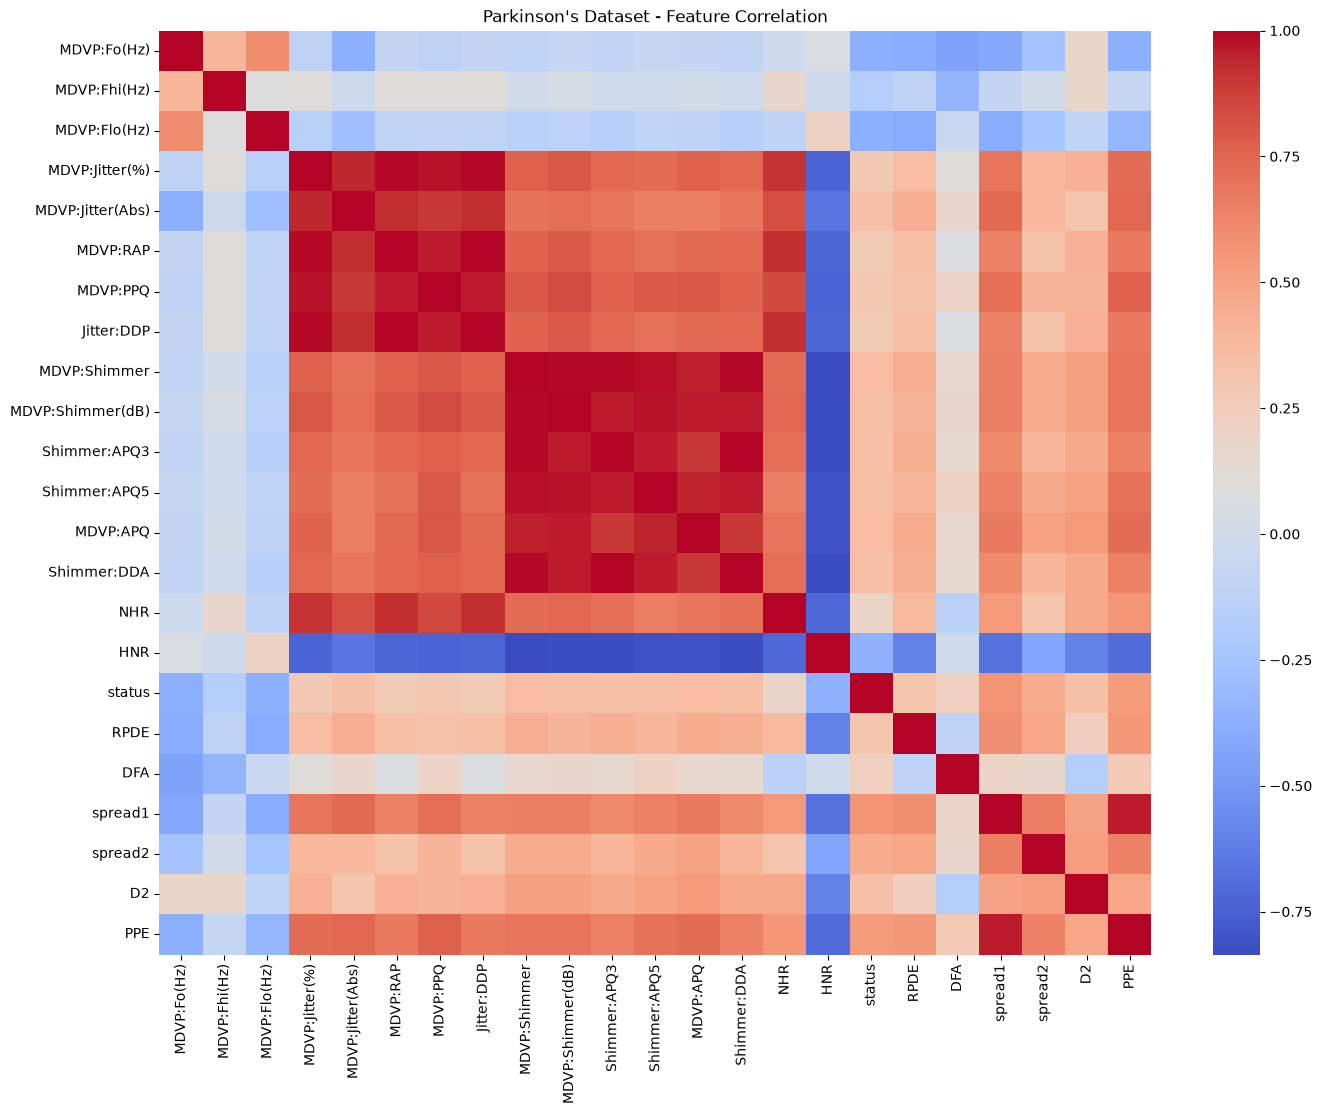

In [12]:
plt.figure(figsize=(16, 12))
sns.heatmap(df.corr(), cmap="coolwarm", annot=False)
plt.title("Parkinson's Dataset - Feature Correlation")
plt.show()

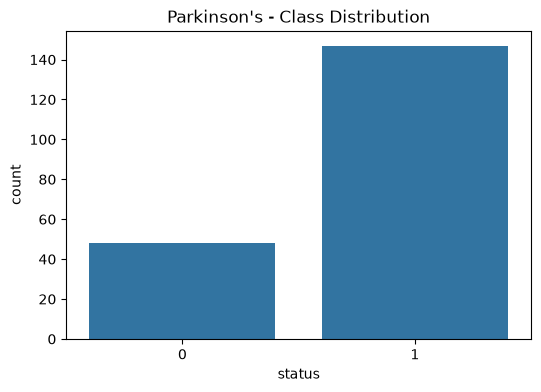

In [13]:
plt.figure(figsize=(6, 4))
sns.countplot(x=target_col, data=df)
plt.title("Parkinson's - Class Distribution")
plt.show()

In [14]:
X = df.drop(target_col, axis=1)
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [15]:
best_model = SVC(kernel="rbf", C=10, gamma="scale", probability=True, class_weight="balanced")
best_model.fit(X_train_scaled, y_train)
print("Model trained successfully")

Model trained successfully


C:\Users\lahar\OneDrive\Desktop\Multi Disease prediction\venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Accuracy: 0.8718
              precision    recall  f1-score   support

           0       0.69      0.90      0.78        10
           1       0.96      0.86      0.91        29

    accuracy                           0.87        39
   macro avg       0.83      0.88      0.85        39
weighted avg       0.89      0.87      0.88        39



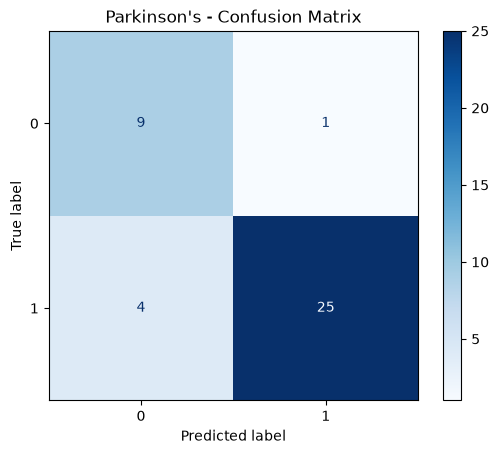

In [16]:
y_pred = best_model.predict(X_test_scaled)
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.4f}")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")
plt.title("Parkinson's - Confusion Matrix")
plt.show()

Accuracy: 0.8718
              precision    recall  f1-score   support

           0       0.69      0.90      0.78        10
           1       0.96      0.86      0.91        29

    accuracy                           0.87        39
   macro avg       0.83      0.88      0.85        39
weighted avg       0.89      0.87      0.88        39



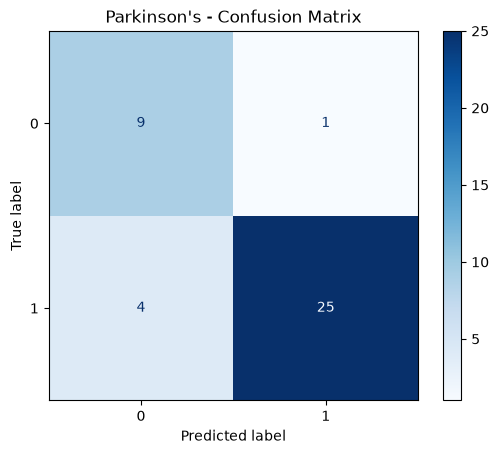

In [17]:
y_pred = best_model.predict(X_test_scaled)
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.4f}")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")
plt.title("Parkinson's - Confusion Matrix")
plt.show()


In [18]:
with open("../models/parkinsons_model.pkl", "wb") as f:
    pickle.dump(best_model, f)
with open("../models/parkinsons_scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)
with open("../models/parkinsons_metrics.pkl", "wb") as f:
    pickle.dump({"accuracy": acc, "best_params": {"kernel": "rbf", "C": 10, "gamma": "scale"}, "feature_order": list(X.columns)}, f)

print("Saved parkinsons model, scaler, metrics.")

Saved parkinsons model, scaler, metrics.
